# Image and labels tiles

Image elements (here the Xenium `morphology_focus` DAPI image and the `he_image` H&E stain) and labels elements (the `cell_labels` segmentation mask) are large 2-D arrays, tens of thousands of pixels on a side.
spatialbatch streams **one tile per cell, centered on the cell**, of every requested image and labels element.
This guide streams **only the pixels**: the expression in the same collection is never read.

The key ideas:

- tiles are **1024 × 1024 pixels** by default: a large context, read in a few large windows from 128-pixel chunks;
- a `transform` crops and augments the **whole batch** on the device, so the model sees the tile size it needs (224 here), with the cell at the center.

If you are new to `spatialbatch`, skim the {doc}`quickstart` first.

## Configure zarrs

In [1]:
import os
import warnings
from pathlib import Path

import zarr

zarr.config.set({"codec_pipeline.path": "zarrs.ZarrsCodecPipeline"})
for msg in (
    "Consolidated metadata is currently not part in the Zarr format 3 specification.*",
    "The index of the dataframe is not monotonic increasing.*",
):
    warnings.filterwarnings("ignore", message=msg)

## Get the data

Tiles are centered on cells, so even an image-only loader needs to know where the cells are: the `cell_circles` shapes and the `table` that annotates them provide the centers (and the row order).

In [2]:
# Xenium stores read with `spatialdata-io`; point SPATIALBATCH_DATA at the folder that holds them.
DATA = Path(os.environ.get("SPATIALBATCH_DATA", "sddb-downloads"))
STORES = [DATA / "6T1aLES2sndpL1bQ0001.zarr", DATA / "ftcwfWqbDwNk5EMp0001.zarr"]
# The collection shared by the scrnaseq, images and multimodal tutorials.
COLLECTION = Path(os.environ.get("SPATIALBATCH_COLLECTION", "sddb_collection.zarr"))

In [3]:
import spatialdata as sd

sdata = sd.read_zarr(STORES[0])
for name in ("morphology_focus", "he_image", "cell_labels"):
    scale0 = next(iter(sdata[name]["scale0"].ds.values()))
    print(f"{name}: {scale0.dims} {scale0.shape} {scale0.dtype}")

no parent found for <ome_zarr.reader.Label object at 0x12d53ba10>: None


no parent found for <ome_zarr.reader.Label object at 0x12c6833b0>: None


morphology_focus: ('c', 'y', 'x') (1, 50965, 53975) uint16
he_image: ('c', 'y', 'x') (3, 50965, 53975) uint8
cell_labels: ('y', 'x') (50965, 53975) uint32


In [4]:
sdata

SpatialData object, with associated Zarr store: sddb-downloads/6T1aLES2sndpL1bQ0001.zarr
├── Images
│     ├── 'he_image': DataTree[cyx] (3, 50965, 53975), (3, 25482, 26987), (3, 12741, 13493), (3, 6370, 6746), (3, 3185, 3373)
│     ├── 'morphology_focus': DataTree[cyx] (1, 50965, 53975), (1, 25482, 26987), (1, 12741, 13493), (1, 6370, 6746), (1, 3185, 3373)
│     └── 'morphology_mip': DataTree[cyx] (1, 50965, 53975), (1, 25482, 26987), (1, 12741, 13493), (1, 6370, 6746), (1, 3185, 3373)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (50965, 53975), (25482, 26987), (12741, 13493), (6370, 6746), (3185, 3373)
│     └── 'nucleus_labels': DataTree[yx] (50965, 53975), (25482, 26987), (12741, 13493), (6370, 6746), (3185, 3373)
├── Points
│     └── 'transcripts': DataFrame with shape: (49291523, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (348141, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (348141, 2) (2D shapes)
│     └── 'nucleus_boundaries

In [5]:
sdata["table"]

AnnData object with n_obs × n_vars = 348141 × 479
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'
    layers: 'csc_counts', None (.X)

## Write the collection (once)

This tutorial, {doc}`scrnaseq`, {doc}`images` and {doc}`multimodal` share **one** collection holding the table, the `morphology_focus` (DAPI) and `he_image` (H&E) images and the `cell_labels` and `nucleus_labels` masks of every slide; each only changes how the {class}`~spatialbatch.Loader` is built.
It is written by whichever tutorial runs first and reused by the others.

`load_table` plays the role of annbatch's `load_adata`: it chooses what of the table is written.
Here we keep the raw counts in `X`, three `obs` columns and the cell coordinates, and drop the duplicate `csc_counts` layer.
It must keep the rows: they are tied to the tiles.

In [6]:
import anndata as ad

from spatialbatch import SpatialDatasetCollection


def _load_table(table: ad.AnnData) -> ad.AnnData:
    return ad.AnnData(
        X=table.X.astype("float32"),  # raw counts, one dtype across slides
        obs=table.obs[["cell_id", "cell_area", "total_counts"]],
        var=table.var,
        obsm={"spatial": table.obsm["spatial"]},
    )


if not COLLECTION.exists():
    SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="w")).add_sdatas(
        STORES,
        region="cell_circles",
        images=["morphology_focus", "he_image"],
        labels=["cell_labels", "nucleus_labels"],
        load_table=_load_table,
    )
collection = SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="r"))
for dataset in collection:
    meta = dataset.attrs["spatialbatch"]
    print(
        f"{dataset.name}: {dataset['obsm']['spatial'].shape[0]:,} cells | tiles {meta['tile_hw']} | "
        f"images {meta['images']} | labels {meta['labels']}"
    )

/dataset_0: 348,141 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']
/dataset_1: 247,876 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']


## Stream image and labels tiles

`table=False` skips the expression; `return_annotations` keeps the `obs` columns to yield (here the cell id).
Each image tile is `(channels, 1024, 1024)` and each labels tile `(1024, 1024)`.
A 1024² uint16 channel is 2 MB, so pixel loaders default to small requests: `chunk_size=16` cells × `preload_nchunks=8` chunks = 128 tiles shuffled together.

In [7]:
import torch

from spatialbatch import Loader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pixels = {"images": ["morphology_focus", "he_image"], "labels": ["cell_labels"], "return_annotations": ["cell_id"]}
loader = Loader(table=False, **pixels, batch_size=32, shuffle=True, to="torch").use_collection(collection)

batch = next(iter(loader))
print("X:", batch["X"])
print(
    "morphology image tiles:",
    tuple(batch["images"]["morphology_focus"].shape),
    batch["images"]["morphology_focus"].dtype,
)
print("he_image tiles:", tuple(batch["images"]["he_image"].shape), batch["images"]["he_image"].dtype)
print("labels tiles:", tuple(batch["labels"]["cell_labels"].shape), batch["labels"]["cell_labels"].dtype)

X: None
morphology image tiles: (32, 1, 1024, 1024) torch.uint16
he_image tiles: (32, 3, 1024, 1024) torch.uint8
labels tiles: (32, 1024, 1024) torch.uint32


## Transforms: augment the batch on the device

`transform` receives the whole batch and returns what the loader yields.
This one, for training:

1. moves the tiles to the device;
2. cuts a 224-pixel crop out of the 1024-pixel tile, jittered by up to 32 pixels around the cell so the model does not learn that cells are always dead-center;
3. turns the labels crop into the **mask of this row's cell** (the label under the tile center);
4. applies the same random 90° rotation to both images and the mask, so they stay aligned;
5. standardizes each tile.

For validation, `v2.CenterCrop` alone gives the deterministic center crop.

In [8]:
CROP, JITTER = 224, 32


def standardize(tiles: torch.Tensor) -> torch.Tensor:
    tiles = torch.log1p(tiles.float())
    mean = tiles.mean(dim=(-2, -1), keepdim=True)
    return (tiles - mean) / tiles.std(dim=(-2, -1), keepdim=True).clamp(min=1e-3)


def train_transform(crop: int = 224, jitter: int = 32):
    def transform(batch):
        images = batch["images"]["morphology_focus"].to(device)
        he_images = batch["images"]["he_image"].to(device)
        labels = batch["labels"]["cell_labels"].to(device)
        tile = images.shape[-1]  # 1024 by default
        cell = labels[:, tile // 2, tile // 2].to(torch.int64)  # the label of each row's own cell
        he_crops, crops, masks = [], [], []
        for i in range(images.shape[0]):
            dy, dx = torch.randint(-jitter, jitter + 1, (2,)).tolist()
            y0, x0 = (tile - crop) // 2 + dy, (tile - crop) // 2 + dx
            k = int(torch.randint(4, ()))
            image = images[i, :, y0 : y0 + crop, x0 : x0 + crop].float()
            he_image = he_images[i, :, y0 : y0 + crop, x0 : x0 + crop].float()
            mask = labels[i, y0 : y0 + crop, x0 : x0 + crop].to(torch.int64) == cell[i]
            crops.append(torch.rot90(image, k, dims=(-2, -1)))
            he_crops.append(torch.rot90(he_image, k, dims=(-2, -1)))
            masks.append(torch.rot90(mask, k, dims=(-2, -1)))
        batch["images"]["morphology_focus"] = standardize(torch.stack(crops))
        batch["images"]["he_image"] = torch.stack(he_crops)
        batch["labels"]["cell_labels"] = torch.stack(masks)
        return batch

    return transform


train_loader = Loader(
    table=False, **pixels, batch_size=32, shuffle=True, to="torch", transform=train_transform(CROP, JITTER)
)
train_loader.use_collection(collection)
batch = next(iter(train_loader))
images, he_images, masks = (
    batch["images"]["morphology_focus"],
    batch["images"]["he_image"],
    batch["labels"]["cell_labels"],
)
print(f"images: {tuple(images.shape)} {images.dtype} on {images.device}")
print(f"he images: {tuple(he_images.shape)} {he_images.dtype} on {he_images.device}")
print(f"masks:  {tuple(masks.shape)} {masks.dtype}")

images: (32, 1, 224, 224) torch.float32 on cpu
he images: (32, 3, 224, 224) torch.float32 on cpu
masks:  (32, 224, 224) torch.bool


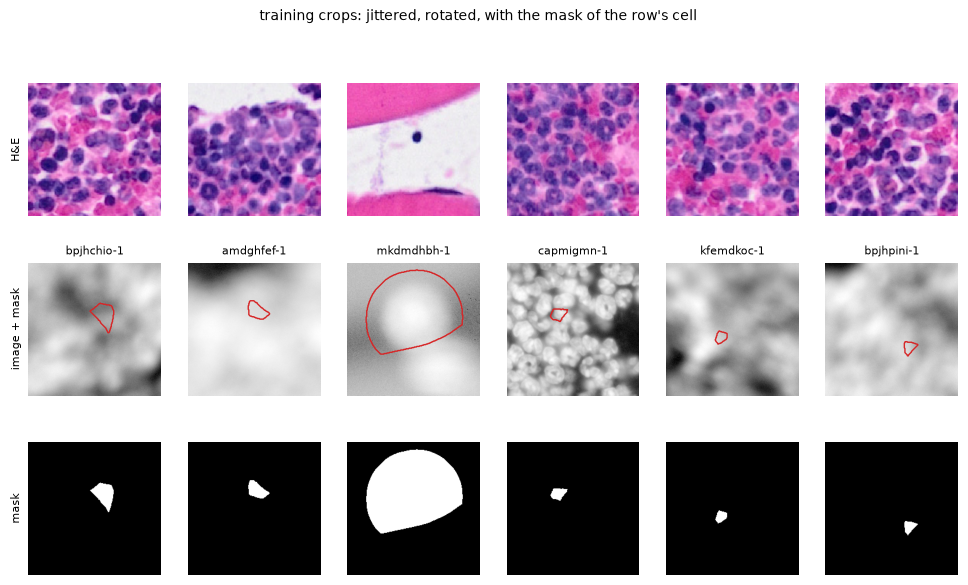

In [9]:
import matplotlib.pyplot as plt
import torch


def as_rgb(tile: torch.Tensor) -> torch.Tensor:
    """A (3, H, W) H&E tile as an (H, W, 3) uint8 image, the layout imshow expects."""
    return tile.permute(1, 2, 0).clamp(0, 255).to(torch.uint8).cpu()


fig, axes = plt.subplots(3, 6, figsize=(12, 6.6))
for j in range(6):
    axes[0, j].imshow(as_rgb(he_images[j]))
    axes[1, j].imshow(images[j, 0].cpu(), cmap="gray")
    axes[1, j].contour(masks[j].cpu(), levels=[0.5], colors="tab:red", linewidths=1)
    axes[1, j].set_title(batch["obs"]["cell_id"].iloc[j], fontsize=8)
    axes[2, j].imshow(masks[j].cpu(), cmap="gray")
for ax in axes.ravel():
    ax.axis("off")
for i, name in enumerate(["H&E", "image + mask", "mask"]):
    axes[i, 0].text(-0.05, 0.5, name, transform=axes[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
fig.suptitle("training crops: jittered, rotated, with the mask of the row's cell", fontsize=10);

## Use the 1024-pixel context at several scales

The large tile is what makes multi-scale inputs cheap: from the same batch, take the 224-pixel center crop for the cell itself, and the whole 1024-pixel tile downsampled to 256 for its tissue neighborhood.

cell: (32, 1, 224, 224)    he_cell: (32, 3, 224, 224)    neighborhood: (32, 1, 256, 256)    he_neighborhood: (32, 3, 256, 256)


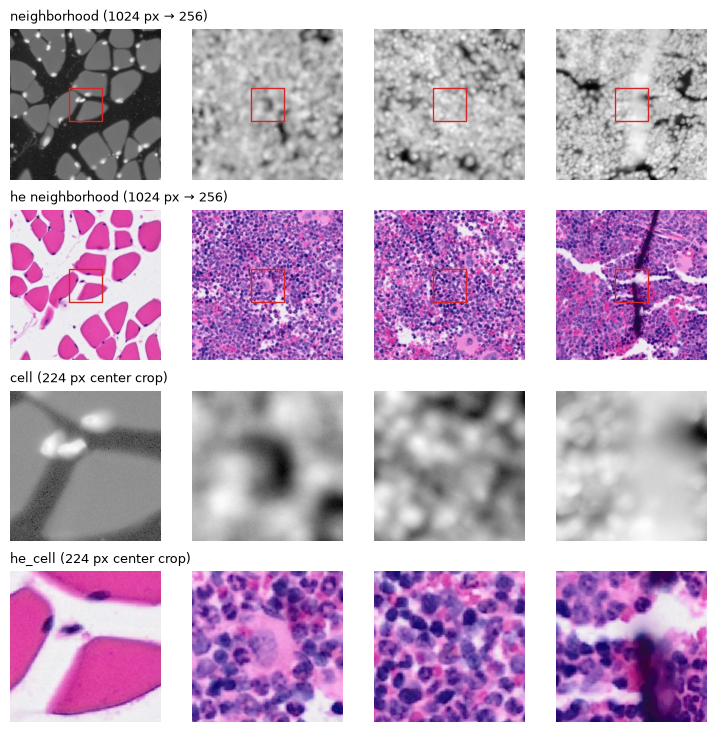

In [10]:
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.transforms import v2


def multiscale(crop: int = 224):
    center = v2.CenterCrop(crop)

    def transform(batch):
        tiles = batch["images"]["morphology_focus"].to(device)
        he_tiles = batch["images"]["he_image"].to(device)
        batch["images"] = {
            "cell": standardize(center(tiles)),
            "he_cell": center(he_tiles).float(),
            "neighborhood": F.avg_pool2d(standardize(tiles), kernel_size=4),  # 1024 -> 256
            "he_neighborhood": TF.resize(he_tiles, (256, 256)),  # 1024 -> 256
        }
        return batch

    return transform


ms_loader = Loader(
    table=False,
    images=["morphology_focus", "he_image"],
    batch_size=32,
    shuffle=True,
    to="torch",
    transform=multiscale(CROP),
)
batch = next(iter(ms_loader.use_collection(collection)))
cell, he_cell, neighborhood, he_neighborhood = (
    batch["images"]["cell"],
    batch["images"]["he_cell"],
    batch["images"]["neighborhood"],
    batch["images"]["he_neighborhood"],
)
print(
    f"cell: {tuple(cell.shape)}    he_cell: {tuple(he_cell.shape)}    neighborhood: {tuple(neighborhood.shape)}    he_neighborhood: {tuple(he_neighborhood.shape)}"
)

c = neighborhood.shape[-1] / 2  # the center of the neighborhood
half = CROP / 4 / 2  # half the cell crop, at 1/4 scale
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for j in range(4):
    axes[0, j].imshow(neighborhood[j, 0].cpu(), cmap="gray")
    axes[1, j].imshow(as_rgb(he_neighborhood[j]))
    axes[2, j].imshow(cell[j, 0].cpu(), cmap="gray")
    axes[3, j].imshow(as_rgb(he_cell[j]))
    for ax in axes[:2, j]:  # outline the cell crop inside both neighborhoods
        ax.add_patch(plt.Rectangle((c - half, c - half), 2 * half, 2 * half, fill=False, color="tab:red"))

for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("neighborhood (1024 px → 256)", loc="left", fontsize=9)
axes[1, 0].set_title("he neighborhood (1024 px → 256)", loc="left", fontsize=9)
axes[2, 0].set_title("cell (224 px center crop)", loc="left", fontsize=9)
axes[3, 0].set_title("he_cell (224 px center crop)", loc="left", fontsize=9);

## Throughput

Tiles are heavy, so we time a fixed number of batches rather than a full pass, including the training transform.

In [11]:
import time

n_batches = 50
start = time.perf_counter()
for i, _ in enumerate(train_loader):
    if i == n_batches:
        break
elapsed = time.perf_counter() - start
n_tiles = n_batches * 32
print(
    f"{n_tiles} cells (1024² image + labels tiles, cropped to {CROP}²) in {elapsed:.1f}s → {n_tiles / elapsed:,.0f} cells/s"
)

1600 cells (1024² image + labels tiles, cropped to 224²) in 9.9s → 161 cells/s


To trade memory for throughput, raise `chunk_size` and `preload_nchunks` (`chunk_size * preload_nchunks` tiles of 2 MB per uint16 channel are held per request), or write a smaller tile with `tile_dim_in_units` if your models never need the 1024-pixel context.

## Images with their own transformation

Tiles are read by slicing only from elements in the pixel grid of the coordinate system.
The `he_image` of these stores already is, so it was written as is above.
An H&E image registered to the slide with a rotation or a scaling is not, and can't be written to a collection as is.
Resample it once onto that grid with {func}`~spatialbatch.align_to_cs`, then write it like any other image:

```python
from spatialbatch import align_to_cs

align_to_cs(path, "he_image", like="morphology_focus")  # adds `he_image_aligned` to the store
collection.add_sdatas([path], images=["morphology_focus", "he_image_aligned"], labels=["cell_labels"])
```

## Next steps

- {doc}`multimodal`: the same tiles together with the cells' expression, feeding a model.
- {doc}`scrnaseq`: the expression alone, from the same collection.